<a href="https://colab.research.google.com/github/Sachin-Abishek/helmet_detection/blob/main/HelmNet.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **Problem Statement**

## **Business Context**

Workplace safety in hazardous environments like construction sites and industrial plants is crucial to prevent accidents and injuries. One of the most important safety measures is ensuring workers wear safety helmets, which protect against head injuries from falling objects and machinery. Non-compliance with helmet regulations increases the risk of serious injuries or fatalities, making effective monitoring essential, especially in large-scale operations where manual oversight is prone to errors and inefficiency.

To overcome these challenges, SafeGuard Corp plans to develop an automated image analysis system capable of detecting whether workers are wearing safety helmets. This system will improve safety enforcement, ensuring compliance and reducing the risk of head injuries. By automating helmet monitoring, SafeGuard aims to enhance efficiency, scalability, and accuracy, ultimately fostering a safer work environment while minimizing human error in safety oversight.

## **Objective**

As a data scientist at SafeGuard Corp, you are tasked with developing an image classification model that classifies images into one of two categories:
- **With Helmet:** Workers wearing safety helmets.
- **Without Helmet:** Workers not wearing safety helmets.

## **Data Description**

The dataset consists of **631 images**, equally divided into two categories:

- **With Helmet:** 311 images showing workers wearing helmets.
- **Without Helmet:** 320 images showing workers not wearing helmets.

**Dataset Characteristics:**
- **Variations in Conditions:** Images include diverse environments such as construction sites, factories, and industrial settings, with variations in lighting, angles, and worker postures to simulate real-world conditions.
- **Worker Activities:** Workers are depicted in different actions such as standing, using tools, or moving, ensuring robust model learning for various scenarios.

# **Installing and Importing the Necessary Libraries**

In [ ]:
!pip install numpy pandas seaborn tensorflow scikit-learn matplotlib

In [ ]:
import tensorflow as tf
print("Num GPUs Available:", len(tf.config.list_physical_devices('GPU')))
print(tf.__version__)

Num GPUs Available: 1
2.19.0


In [ ]:
import os
import random
import numpy as np                                                                         # Importing numpy for Matrix Operations
import pandas as pd                                                                        # Importing pandas to read CSV files
import seaborn as sns
import matplotlib.image as mpimg                                                           # Importing matplotlib for Plotting and visualizing images
import matplotlib.pyplot as plt
import math                                                                                # Importing math module to perform mathematical operations
import cv2


# Tensorflow modules
import tensorflow as tf
from tensorflow.keras.preprocessing.image import ImageDataGenerator                                                     # Importing the ImageDataGenerator for data augmentation
from tensorflow.keras.models import Sequential                                                                          # Importing the sequential module to define a sequential model
from tensorflow.keras.layers import Dense,Dropout,Flatten,Conv2D,MaxPooling2D,BatchNormalization,GlobalAveragePooling2D # Defining all the layers to build our CNN Model
from tensorflow.keras.optimizers import Adam,SGD                                                                        # Importing the optimizers which can be used in our model
from sklearn import preprocessing                                                                                       # Importing the preprocessing module to preprocess the data
from sklearn.model_selection import train_test_split                                                                    # Importing train_test_split function to split the data into train and test
from sklearn.metrics import confusion_matrix                                                                            # Importing confusion_matrix to plot the confusion matrix
from tensorflow.keras.models import Model
from tensorflow.keras.applications.vgg16 import VGG16, preprocess_input
from tensorflow.keras import backend as K
import gc

# Display images using OpenCV
from google.colab.patches import cv2_imshow                                              # Importing cv2_imshow from google.patches to display images

#Imports functions for evaluating the performance of machine learning models
from sklearn.metrics import confusion_matrix, f1_score,accuracy_score, recall_score, precision_score, classification_report
from sklearn.metrics import mean_squared_error as mse

# Ignore warnings
import warnings
warnings.filterwarnings('ignore')

In [ ]:
# Set the seed using keras.utils.set_random_seed. This will set:
# 1) `numpy` seed
# 2) backend random seed
# 3) `python` random seed
tf.keras.utils.set_random_seed(800)

# **Data Overview**


##Loading the data

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
#import the data along with label from the drive
image_data = '/content/drive/MyDrive/dataset/Helmnet_Data/images_proj.npy'
image_label = '/content/drive/MyDrive/dataset/Helmnet_Data/Labels_proj.csv'

In [ ]:
#Load the images and labels
images = np.load(image_data)
labels = pd.read_csv(image_label)

#Data Overview

In [ ]:
print("Shape of images",images.shape)
print('Shape of labels', labels.shape)

Shape of images (631, 200, 200, 3)
Shape of labels (631, 1)


Observation   
There are 631 RGB images of size 200 x 200 x 3 with each image having 3 channels.  
There are 631 labels.

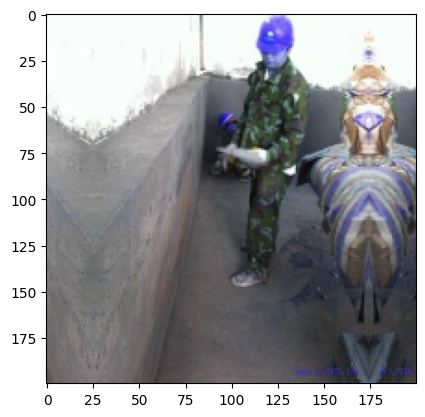

In [ ]:
#Loading an image from the dataset
plt.imshow(images[60]);

# **Exploratory Data Analysis**

###Plot random images from each of the classes and print their corresponding labels.

In [ ]:
def plot_images(images,labels):
  keys=dict(labels['Label'])
  rows = 3                                                                        # Defining number of rows=3
  cols = 4                                                                        # Defining number of columns=4
  fig = plt.figure(figsize=(10, 8))                                               # Defining the figure size to 10x8
  for i in range(cols):
      for j in range(rows):
          random_index = np.random.randint(0, len(labels))                        # Generating random indices from the data and plotting the images
          ax = fig.add_subplot(rows, cols, i * rows + j + 1)                      # Adding subplots with 3 rows and 4 columns
          ax.imshow(images[random_index, :])                                      # Plotting the image
          ax.set_title(keys[random_index])
  plt.show()


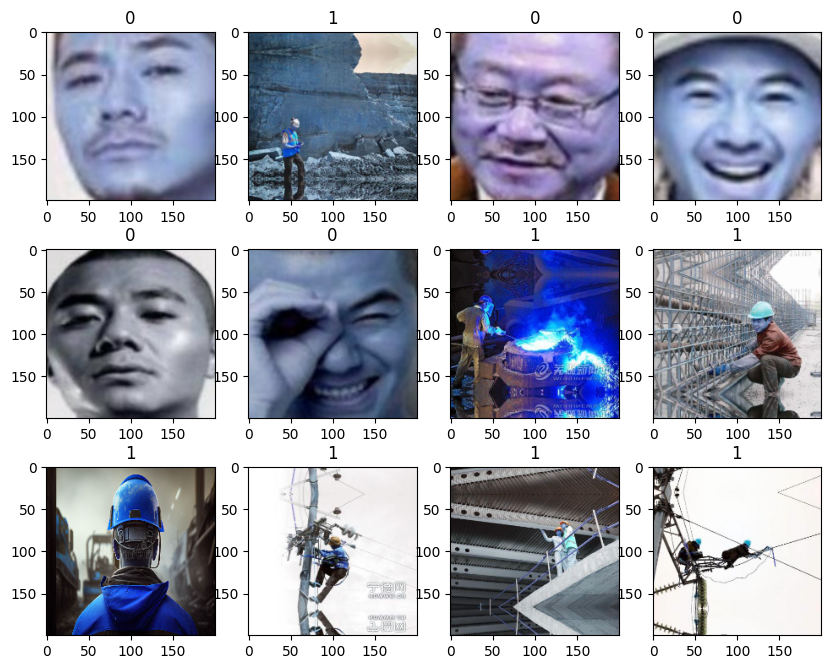

In [ ]:
plot_images(images,labels)

Observation:
* The images with person with helmet have the individuals working in various environments.
* The images with person without helmet have the person's face.
* Here the label 1 represents the images with person with helmet.  
* While the label 0 represents the images with person without helmet.

## Checking for class imbalance


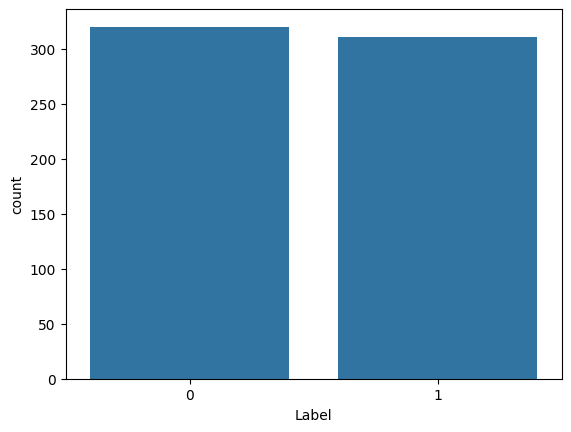

In [ ]:
sns.countplot(x='Label',data=labels);

Observation:  
* The dataset is almost even.
* The class 0 (without helmet) has slightly more images than class 1 (with helmet).

# **Data Preprocessing**

## Converting images to grayscale

In [ ]:
# Function to plot the original and processed images side by side
def grid_plot(img1,img2,gray=False):
    fig, axes = plt.subplots(1, 2, figsize=(12, 5))
    axes[0].imshow(img1)
    axes[0].set_title('Original Image')
    axes[0].axis('off')

    if gray:
      axes[1].imshow(img2,cmap='gray')
    else:
      axes[1].imshow(img2)
    axes[1].set_title('Processed Image')
    axes[1].axis('off')

    plt.show()

In [ ]:
gray_images = []
for i in range(len(images)):
  gray_images.append(cv2.cvtColor(images[i], cv2.COLOR_RGB2GRAY))

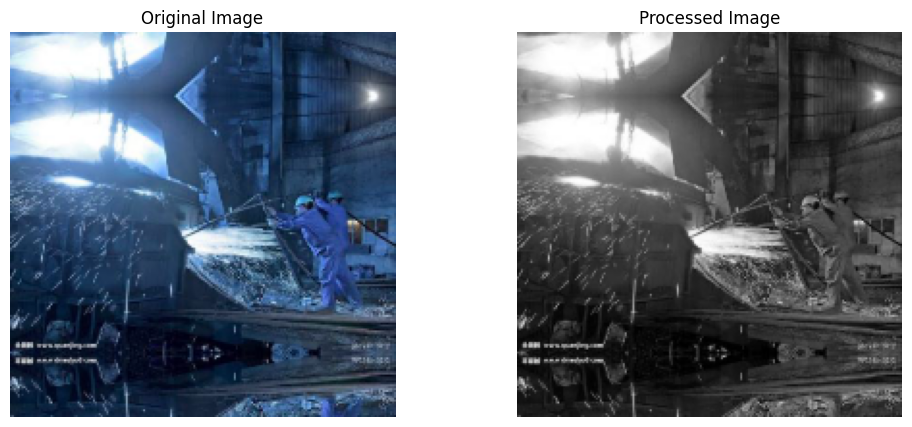

In [ ]:
n = 5
# plotting the original and preprocessed image
grid_plot(images[n],gray_images[n],gray=True)

### Splitting the dataset



* The dataset has only 631 images, we will only use 10% of our data for testing, 10% of our data for validation and 80% of our data for training.  
* We shall use the train_test_split() function from scikit-learn.

In [ ]:
from sklearn.model_selection import train_test_split
X_train, X_temp, y_train, y_temp = train_test_split(np.array(images),labels , test_size=0.2, random_state=42,stratify=labels)
X_val, X_test, y_val, y_test = train_test_split(X_temp,y_temp , test_size=0.5, random_state=42,stratify=y_temp)

In [ ]:
print(X_train.shape,y_train.shape)
print(X_val.shape,y_val.shape)
print(X_test.shape,y_test.shape)

(504, 200, 200, 3) (504, 1)
(63, 200, 200, 3) (63, 1)
(64, 200, 200, 3) (64, 1)


### Data Normalization

In [ ]:
# Normalizing the image pixels
X_train_normalized = X_train.astype('float32')/255.0
X_val_normalized = X_val.astype('float32')/255.0
X_test_normalized = X_test.astype('float32')/255.0

# **Model Building**

##Model Evaluation Criterion

## Utility Functions

In [ ]:
# defining a function to compute different metrics to check performance of a classification model built using statsmodels
def model_performance_classification(model, predictors, target):
    """
    Function to compute different metrics to check classification model performance

    model: classifier
    predictors: independent variables
    target: dependent variable
    """

    # checking which probabilities are greater than threshold
    pred = model.predict(predictors).reshape(-1)>0.5

    target = target.to_numpy().reshape(-1)


    acc = accuracy_score(target, pred)  # to compute Accuracy
    recall = recall_score(target, pred, average='weighted')  # to compute Recall
    precision = precision_score(target, pred, average='weighted')  # to compute Precision
    f1 = f1_score(target, pred, average='weighted')  # to compute F1-score

    # creating a dataframe of metrics
    df_perf = pd.DataFrame({"Accuracy": acc, "Recall": recall, "Precision": precision, "F1 Score": f1,},index=[0],)

    return df_perf

In [ ]:
def plot_confusion_matrix(model,predictors,target,ml=False):
    """
    Function to plot the confusion matrix

    model: classifier
    predictors: independent variables
    target: dependent variable
    ml: To specify if the model used is an sklearn ML model or not (True means ML model)
    """

    # checking which probabilities are greater than threshold
    pred = model.predict(predictors).reshape(-1)>0.5

    target = target.to_numpy().reshape(-1)

    # Plotting the Confusion Matrix using confusion matrix() function which is also predefined tensorflow module
    confusion_matrix = tf.math.confusion_matrix(target,pred)
    f, ax = plt.subplots(figsize=(10, 8))
    sns.heatmap(
        confusion_matrix,
        annot=True,
        linewidths=.4,
        fmt="d",
        square=True,
        ax=ax
    )
    plt.show()

##Model 1: Simple Convolutional Neural Network (CNN)

In [ ]:
# Intializing a sequential model
model = Sequential()

# Adding first conv layer with 64 filters and kernel size 3x3 , padding 'same' provides the output size same as the input size
model.add(Conv2D(64, (3, 3), activation='relu', padding="same", input_shape=(200, 200, 3)))

# Adding max pooling to reduce the size of output of first conv layer
model.add(MaxPooling2D((2, 2), padding = 'same'))

model.add(Conv2D(32, (3, 3), activation='relu', padding="same"))
model.add(MaxPooling2D((2, 2), padding = 'same'))
model.add(Conv2D(32, (3, 3), activation='relu', padding="same"))
model.add(MaxPooling2D((2, 2), padding = 'same'))

# flattening the output of the conv layer after max pooling to make it ready for creating dense connections
model.add(Flatten())

# Adding a fully connected dense layer with 100 neurons
model.add(Dense(100, activation='relu'))

# Binary output: 1 neuron + sigmoid
model.add(Dense(1, activation='sigmoid'))

# Binary loss
opt = SGD(learning_rate=0.01, momentum=0.9)
model.compile(optimizer=opt,
              loss='binary_crossentropy',
              metrics=['accuracy'])

# Generating the summary of the model
model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 200, 200, 64)   │         1,792 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 100, 100, 64)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 100, 100, 32)   │        18,464 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 50, 50, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 50, 50, 32)     │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 25, 25, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 20000)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 100)            │     2,000,100 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │           101 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,029,705 (7.74 MB)

 Trainable params: 2,029,705 (7.74 MB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
CNN_Model = model.fit(
            X_train_normalized, y_train,
            epochs=15,
            validation_split=0.1,
            shuffle=True,
            batch_size=64,
            verbose=2
)

Epoch 1/15
8/8 - 9s - 1s/step - accuracy: 0.5011 - loss: 0.6804 - val_accuracy: 0.5294 - val_loss: 0.6336
Epoch 2/15
8/8 - 1s - 136ms/step - accuracy: 0.6843 - loss: 0.6034 - val_accuracy: 0.4706 - val_loss: 0.8864
Epoch 3/15
8/8 - 1s - 120ms/step - accuracy: 0.7506 - loss: 0.5344 - val_accuracy: 0.6275 - val_loss: 0.8911
Epoch 4/15
8/8 - 1s - 180ms/step - accuracy: 0.7660 - loss: 0.4924 - val_accuracy: 0.9608 - val_loss: 0.2476
Epoch 5/15
8/8 - 1s - 143ms/step - accuracy: 0.9338 - loss: 0.2243 - val_accuracy: 0.9216 - val_loss: 0.2155
Epoch 6/15
8/8 - 1s - 162ms/step - accuracy: 0.8764 - loss: 0.3465 - val_accuracy: 0.6863 - val_loss: 0.5433
Epoch 7/15
8/8 - 2s - 287ms/step - accuracy: 0.9117 - loss: 0.3252 - val_accuracy: 0.9412 - val_loss: 0.1128
Epoch 8/15
8/8 - 1s - 133ms/step - accuracy: 0.9536 - loss: 0.1460 - val_accuracy: 0.9412 - val_loss: 0.2091
Epoch 9/15
8/8 - 1s - 125ms/step - accuracy: 0.9316 - loss: 0.1927 - val_accuracy: 0.9608 - val_loss: 0.1441
Epoch 10/15
8/8 - 1s -

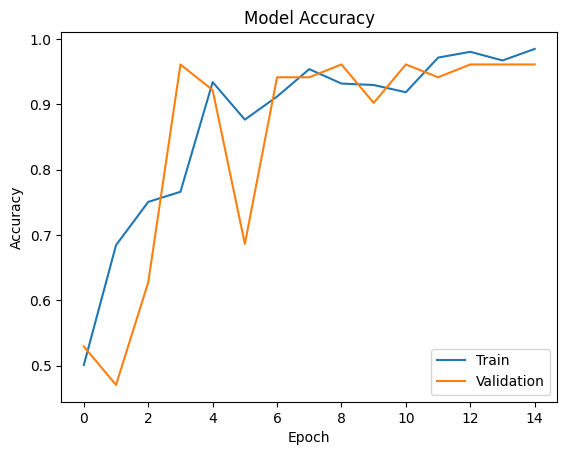

In [ ]:
plt.plot(CNN_Model.history['accuracy'])
plt.plot(CNN_Model.history['val_accuracy'])
plt.title('Model Accuracy')
plt.ylabel('Accuracy')
plt.xlabel('Epoch')
plt.legend(['Train', 'Validation'], loc='lower right')
plt.show()

In [ ]:
CNN_train_perf = model_performance_classification(model, X_train_normalized,y_train)

print("Train performance metrics")
print(CNN_train_perf)

16/16 ━━━━━━━━━━━━━━━━━━━━ 1s 48ms/step
Train performance metrics
   Accuracy    Recall  Precision  F1 Score
0  0.968254  0.968254   0.969296  0.968224


16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step


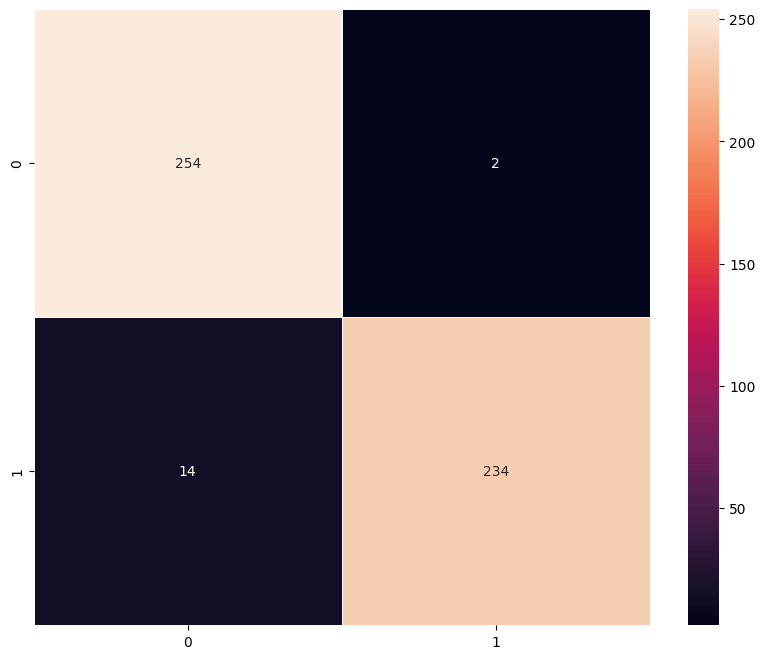

In [ ]:
plot_confusion_matrix(model,X_train_normalized,y_train)

In [ ]:
CNN_valid_perf = model_performance_classification(model, X_val_normalized,y_val)

print("Validation performance metrics")
print(CNN_valid_perf)

2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 295ms/step
Validation performance metrics
   Accuracy    Recall  Precision  F1 Score
0  0.968254  0.968254   0.970121  0.968206


2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 26ms/step


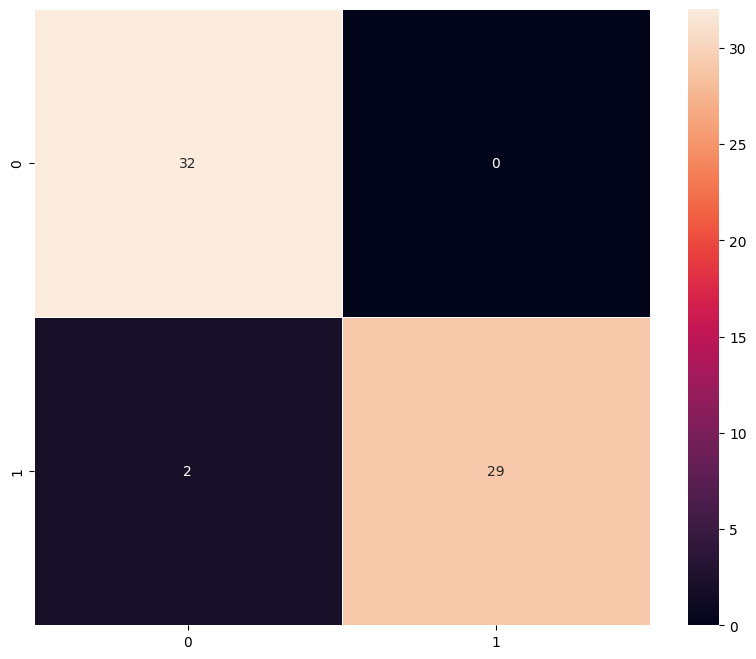

In [ ]:
plot_confusion_matrix(model, X_val_normalized,y_val)

Observation :
* Although,The training accuracy is commendable, it can be seen that the model has more accuracy value for the validation set as the dataset is small.


### Vizualizing the predictions of CNN Model

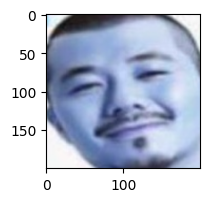

1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 553ms/step
Predicted Probability: 0.0009368034
Predicted Label: 0
True Label: Label    0
Name: 603, dtype: int64


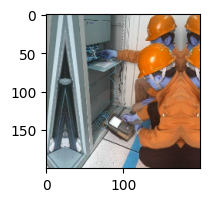

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 28ms/step
Predicted Probability: 0.999987
Predicted Label: 1
True Label: Label    1
Name: 59, dtype: int64


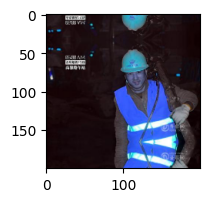

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 30ms/step
Predicted Probability: 0.88083786
Predicted Label: 1
True Label: Label    1
Name: 175, dtype: int64


In [ ]:
# Visualizing the predicted and correct label of images from validation data
# Sample 1
plt.figure(figsize=(2,2))
plt.imshow(X_val[2])
plt.show()

pred_prob = model.predict(X_val_normalized[2].reshape(1,200,200,3))[0][0]
pred_label = 1 if pred_prob > 0.5 else 0

print("Predicted Probability:", pred_prob)
print("Predicted Label:", pred_label)
print("True Label:", y_val.iloc[2])

# Sample 2
plt.figure(figsize=(2,2))
plt.imshow(X_val[10])
plt.show()

pred_prob = model.predict(X_val_normalized[10].reshape(1,200,200,3))[0][0]
pred_label = 1 if pred_prob > 0.5 else 0

print("Predicted Probability:", pred_prob)
print("Predicted Label:", pred_label)
print("True Label:", y_val.iloc[10])

# Sample 3
plt.figure(figsize=(2,2))
plt.imshow(X_val[23])
plt.show()

pred_prob = model.predict(X_val_normalized[23].reshape(1,200,200,3))[0][0]
pred_label = 1 if pred_prob > 0.5 else 0

print("Predicted Probability:", pred_prob)
print("Predicted Label:", pred_label)
print("True Label:", y_val.iloc[23])



Let us preprocess the images for training using VGG Base 16 model.

In [ ]:
X_train_pp = preprocess_input(X_train.copy())
X_val_pp   = preprocess_input(X_val.copy())
X_test_pp  = preprocess_input(X_test.copy())

In [ ]:
# Epochs
epochs = 20
# Batch size
batch_size = 16

## Model 2: (VGG-16 (Base))

In [ ]:
K.clear_session()
gc.collect()


0

In [ ]:
vgg_model = VGG16(weights='imagenet',include_top=False,input_shape=(200,200,3))
vgg_model.summary()

Model: "vgg16"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 200, 200, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_conv1 (Conv2D)           │ (None, 200, 200, 64)   │         1,792 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_conv2 (Conv2D)           │ (None, 200, 200, 64)   │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_pool (MaxPooling2D)      │ (None, 100, 100, 64)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_conv1 (Conv2D)           │ (None, 100, 100, 128)  │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_conv2 (Conv2D)           │ (None, 100, 100, 128)  │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_pool (MaxPooling2D)      │ (None, 50, 50, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv1 (Conv2D)           │ (None, 50, 50, 256)    │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv2 (Conv2D)           │ (None, 50, 50, 256)    │       590,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv3 (Conv2D)           │ (None, 50, 50, 256)    │       590,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_pool (MaxPooling2D)      │ (None, 25, 25, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_conv1 (Conv2D)           │ (None, 25, 25, 512)    │     1,180,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_conv2 (Conv2D)           │ (None, 25, 25, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_conv3 (Conv2D)           │ (None, 25, 25, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_pool (MaxPooling2D)      │ (None, 12, 12, 512)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_conv1 (Conv2D)           │ (None, 12, 12, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_conv2 (Conv2D)           │ (None, 12, 12, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_conv3 (Conv2D)           │ (None, 12, 12, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_pool (MaxPooling2D)      │ (None, 6, 6, 512)      │             0 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 14,714,688 (56.13 MB)

 Trainable params: 14,714,688 (56.13 MB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
# Making all the layers of the VGG model non-trainable. i.e. freezing them
for layer in vgg_model.layers:
    layer.trainable = False

In [ ]:
model_1 = Sequential()

# Adding the convolutional part of the VGG16 model from above
model_1.add(vgg_model)

# Aggregating spatial information across feature maps using Global Average Pooling
model_1.add(GlobalAveragePooling2D())

# Adding a dense output layer
model_1.add(Dense(1, activation='sigmoid'))

In [ ]:
opt=Adam()
# Compile model
model_1.compile(optimizer=opt, loss='binary_crossentropy', metrics=['accuracy'])

In [ ]:
# Generating the summary of the model
model_1.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ vgg16 (Functional)              │ (None, 6, 6, 512)      │    14,714,688 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 512)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 1)              │           513 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 14,715,201 (56.13 MB)

 Trainable params: 513 (2.00 KB)

 Non-trainable params: 14,714,688 (56.13 MB)

In [ ]:
train_datagen = ImageDataGenerator()

In [ ]:
history_vgg16 = model_1.fit(train_datagen.flow(X_train_normalized,y_train,
                                       batch_size=batch_size,
                                       seed=42,
                                       shuffle=True),
                    epochs=epochs,
                    steps_per_epoch=X_train_pp.shape[0] // batch_size,
                    validation_data=(X_val_normalized,y_val),
                    verbose=1)

Epoch 1/20
31/31 ━━━━━━━━━━━━━━━━━━━━ 8s 176ms/step - accuracy: 0.6358 - loss: 0.6568 - val_accuracy: 1.0000 - val_loss: 0.5114
Epoch 2/20
31/31 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - accuracy: 1.0000 - loss: 0.5169 - val_accuracy: 1.0000 - val_loss: 0.5067
Epoch 3/20
31/31 ━━━━━━━━━━━━━━━━━━━━ 3s 100ms/step - accuracy: 0.9969 - loss: 0.4780 - val_accuracy: 1.0000 - val_loss: 0.3844
Epoch 4/20
31/31 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - accuracy: 1.0000 - loss: 0.3900 - val_accuracy: 1.0000 - val_loss: 0.3812
Epoch 5/20
31/31 ━━━━━━━━━━━━━━━━━━━━ 3s 102ms/step - accuracy: 0.9973 - loss: 0.3631 - val_accuracy: 1.0000 - val_loss: 0.2969
Epoch 6/20
31/31 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - accuracy: 1.0000 - loss: 0.3128 - val_accuracy: 1.0000 - val_loss: 0.2947
Epoch 7/20
31/31 ━━━━━━━━━━━━━━━━━━━━ 3s 109ms/step - accuracy: 1.0000 - loss: 0.2819 - val_accuracy: 1.0000 - val_loss: 0.2374
Epoch 8/20
31/31 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - accuracy: 1.0000 - loss: 0.2364 - val_accuracy: 1.0000

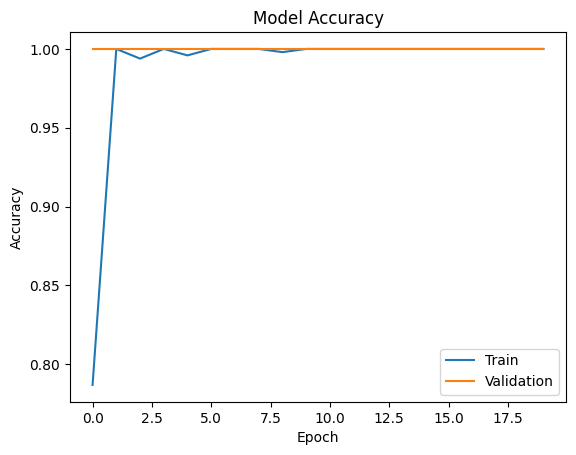

In [ ]:
plt.plot(history_vgg16.history['accuracy'])
plt.plot(history_vgg16.history['val_accuracy'])
plt.title('Model Accuracy')
plt.ylabel('Accuracy')
plt.xlabel('Epoch')
plt.legend(['Train', 'Validation'], loc='lower right')
plt.show()

In [ ]:
model_1_train_perf = model_performance_classification(model_1, X_train_pp,y_train)

print("Train performance metrics")
print(model_1_train_perf)

16/16 ━━━━━━━━━━━━━━━━━━━━ 4s 194ms/step
Train performance metrics
   Accuracy    Recall  Precision  F1 Score
0  0.964286  0.964286   0.966702   0.96426


16/16 ━━━━━━━━━━━━━━━━━━━━ 3s 160ms/step


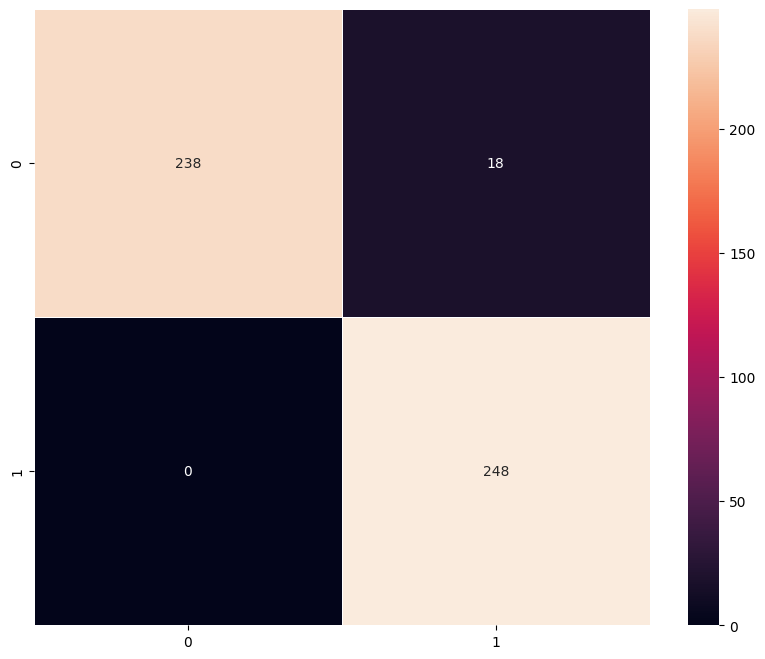

In [ ]:
plot_confusion_matrix(model_1,X_train_pp,y_train)

In [ ]:
model_1_valid_perf = model_performance_classification(model_1, X_val_pp,y_val)

print("Validation performance metrics")
print(model_1_valid_perf)

2/2 ━━━━━━━━━━━━━━━━━━━━ 1s 562ms/step
Validation performance metrics
   Accuracy    Recall  Precision  F1 Score
0  0.984127  0.984127   0.984623  0.984127


2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 165ms/step


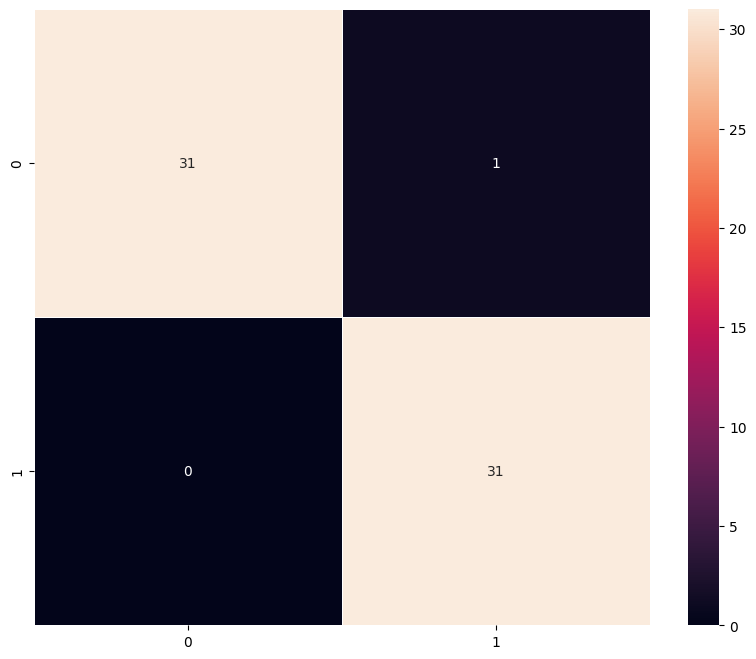

In [ ]:
plot_confusion_matrix(model_1,X_val_pp,y_val)

Observation:
* This model does suffer from overfitting.
* The training and validation accuracy are almost same.

### Visualizing the prediction of VGG Base16 Model

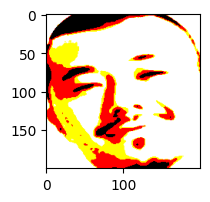

1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 1s/step


Predicted Probability: 5.616413e-05
Predicted Label: 0
True Label: Label    0
Name: 603, dtype: int64


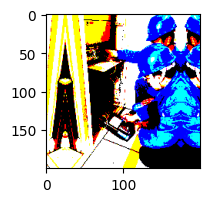

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 33ms/step


Predicted Probability: 1.0
Predicted Label: 1
True Label: Label    1
Name: 59, dtype: int64


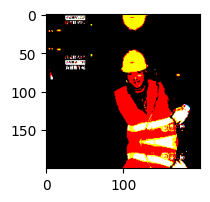

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 35ms/step
Predicted Probability: 1.0
Predicted Label: 1
True Label: Label    1
Name: 175, dtype: int64


In [ ]:
# Visualizing the predicted and correct label of images from test data
# Sample 1
plt.figure(figsize=(2,2))
plt.imshow(X_val_pp[2])
plt.show()

pred_prob = model_1.predict(X_val_pp[2].reshape(1,200,200,3))[0][0]
pred_label = 1 if pred_prob > 0.5 else 0

print("Predicted Probability:", pred_prob)
print("Predicted Label:", pred_label)
print("True Label:", y_val.iloc[2])

# Sample 2
plt.figure(figsize=(2,2))
plt.imshow(X_val_pp[10])
plt.show()

pred_prob = model_1.predict(X_val_pp[10].reshape(1,200,200,3))[0][0]
pred_label = 1 if pred_prob > 0.5 else 0

print("Predicted Probability:", pred_prob)
print("Predicted Label:", pred_label)
print("True Label:", y_val.iloc[10])

# Sample 3
plt.figure(figsize=(2,2))
plt.imshow(X_val_pp[23])
plt.show()

pred_prob = model_1.predict(X_val_pp[23].reshape(1,200,200,3))[0][0]
pred_label = 1 if pred_prob > 0.5 else 0

print("Predicted Probability:", pred_prob)
print("Predicted Label:", pred_label)
print("True Label:", y_val.iloc[23])

## Model 3: (VGG-16 (Base + FFNN))

In [ ]:
K.clear_session()
gc.collect()


0

In [ ]:
vgg_model = VGG16(weights='imagenet',include_top=False,input_shape=(200,200,3))
vgg_model.summary()

Model: "vgg16"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 200, 200, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_conv1 (Conv2D)           │ (None, 200, 200, 64)   │         1,792 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_conv2 (Conv2D)           │ (None, 200, 200, 64)   │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_pool (MaxPooling2D)      │ (None, 100, 100, 64)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_conv1 (Conv2D)           │ (None, 100, 100, 128)  │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_conv2 (Conv2D)           │ (None, 100, 100, 128)  │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_pool (MaxPooling2D)      │ (None, 50, 50, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv1 (Conv2D)           │ (None, 50, 50, 256)    │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv2 (Conv2D)           │ (None, 50, 50, 256)    │       590,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv3 (Conv2D)           │ (None, 50, 50, 256)    │       590,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_pool (MaxPooling2D)      │ (None, 25, 25, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_conv1 (Conv2D)           │ (None, 25, 25, 512)    │     1,180,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_conv2 (Conv2D)           │ (None, 25, 25, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_conv3 (Conv2D)           │ (None, 25, 25, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_pool (MaxPooling2D)      │ (None, 12, 12, 512)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_conv1 (Conv2D)           │ (None, 12, 12, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_conv2 (Conv2D)           │ (None, 12, 12, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_conv3 (Conv2D)           │ (None, 12, 12, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_pool (MaxPooling2D)      │ (None, 6, 6, 512)      │             0 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 14,714,688 (56.13 MB)

 Trainable params: 14,714,688 (56.13 MB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
# Making all the layers of the VGG model non-trainable. i.e. freezing them
for layer in vgg_model.layers:
    layer.trainable = False

In [ ]:
model_2 = Sequential()

# Adding the convolutional part of the VGG16 model from above
model_2.add(vgg_model)

# Aggregating spatial information across feature maps using Global Average Pooling
model_2.add(Faltten())

#Adding the Feed Forward neural network
model_2.add(Dense(32,activation='relu'))
model_2.add(Dropout(rate=0.5))

# Adding a dense output layer
model_2.add(Dense(1, activation='sigmoid'))

In [ ]:
opt = Adam()

In [ ]:
# Compile model
model_2.compile(optimizer=opt, loss='binary_crossentropy', metrics=['accuracy'])

In [ ]:
# Generating the summary of the model
model_2.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ vgg16 (Functional)              │ (None, 6, 6, 512)      │    14,714,688 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 512)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 32)             │        16,416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 14,731,137 (56.19 MB)

 Trainable params: 16,449 (64.25 KB)

 Non-trainable params: 14,714,688 (56.13 MB)

In [ ]:
train_datagen = ImageDataGenerator()

In [ ]:
history_vgg16 = model_2.fit(train_datagen.flow(X_train_pp,y_train,
                                       batch_size=batch_size,
                                       seed=42,
                                       shuffle=True),
                    epochs=epochs,
                    steps_per_epoch=X_train_pp.shape[0] // batch_size,
                    validation_data=(X_val_pp,y_val),
                    verbose=1)

Epoch 1/20
31/31 ━━━━━━━━━━━━━━━━━━━━ 9s 209ms/step - accuracy: 0.7796 - loss: 1.1587 - val_accuracy: 1.0000 - val_loss: 2.2152e-04
Epoch 2/20
31/31 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - accuracy: 0.8750 - loss: 0.2406 - val_accuracy: 1.0000 - val_loss: 2.0703e-04
Epoch 3/20
31/31 ━━━━━━━━━━━━━━━━━━━━ 3s 101ms/step - accuracy: 0.9800 - loss: 0.0348 - val_accuracy: 1.0000 - val_loss: 1.2162e-04
Epoch 4/20
31/31 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - accuracy: 1.0000 - loss: 8.4093e-04 - val_accuracy: 1.0000 - val_loss: 1.2059e-04
Epoch 5/20
31/31 ━━━━━━━━━━━━━━━━━━━━ 3s 108ms/step - accuracy: 0.9922 - loss: 0.0360 - val_accuracy: 1.0000 - val_loss: 2.2867e-04
Epoch 6/20
31/31 ━━━━━━━━━━━━━━━━━━━━ 1s 18ms/step - accuracy: 1.0000 - loss: 1.0662e-05 - val_accuracy: 1.0000 - val_loss: 2.3330e-04
Epoch 7/20
31/31 ━━━━━━━━━━━━━━━━━━━━ 4s 117ms/step - accuracy: 0.9910 - loss: 0.0187 - val_accuracy: 1.0000 - val_loss: 3.8393e-05
Epoch 8/20
31/31 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - accuracy: 1.0000 -

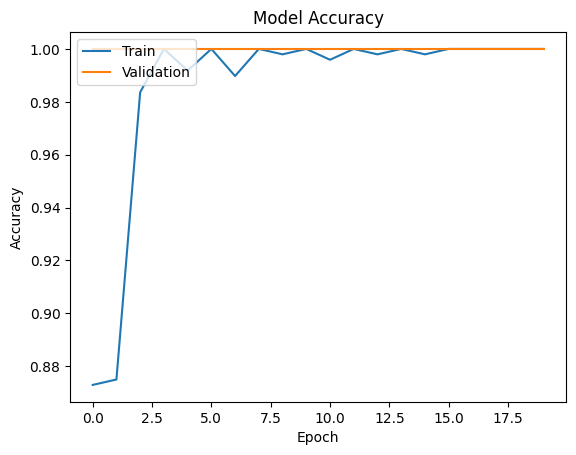

In [ ]:
plt.plot(history_vgg16.history['accuracy'])
plt.plot(history_vgg16.history['val_accuracy'])
plt.title('Model Accuracy')
plt.ylabel('Accuracy')
plt.xlabel('Epoch')
plt.legend(['Train', 'Validation'], loc='upper left')
plt.show()

In [ ]:
model_2_train_perf = model_performance_classification(model_2, X_train_pp,y_train)

print("Train performance metrics")
print(model_2_train_perf)

16/16 ━━━━━━━━━━━━━━━━━━━━ 4s 199ms/step
Train performance metrics
   Accuracy  Recall  Precision  F1 Score
0       1.0     1.0        1.0       1.0


16/16 ━━━━━━━━━━━━━━━━━━━━ 3s 157ms/step


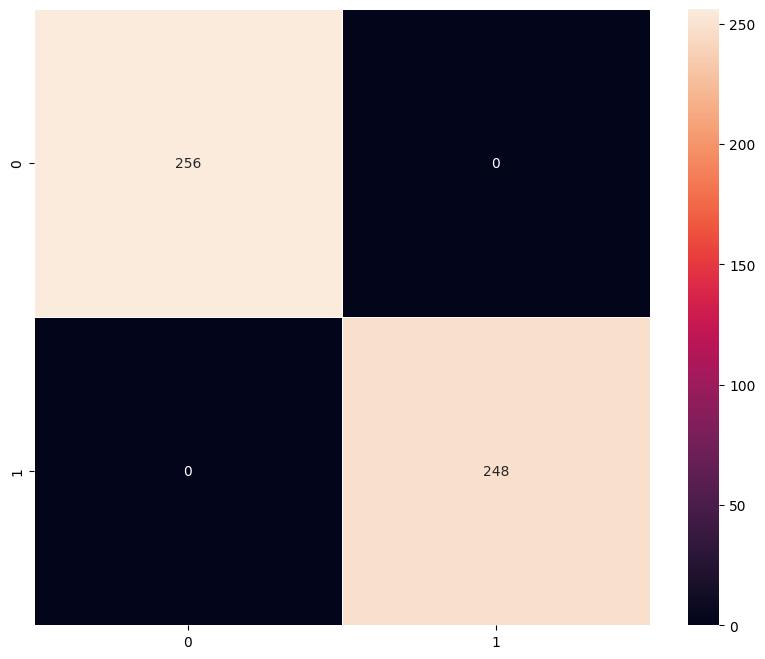

In [ ]:
plot_confusion_matrix(model_2,X_train_pp,y_train)

In [ ]:
model_2_valid_perf = model_performance_classification(model_2, X_val_pp,y_val)

print("Validation performance metrics")
print(model_2_valid_perf)

2/2 ━━━━━━━━━━━━━━━━━━━━ 1s 542ms/step
Validation performance metrics
   Accuracy  Recall  Precision  F1 Score
0       1.0     1.0        1.0       1.0


2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 163ms/step


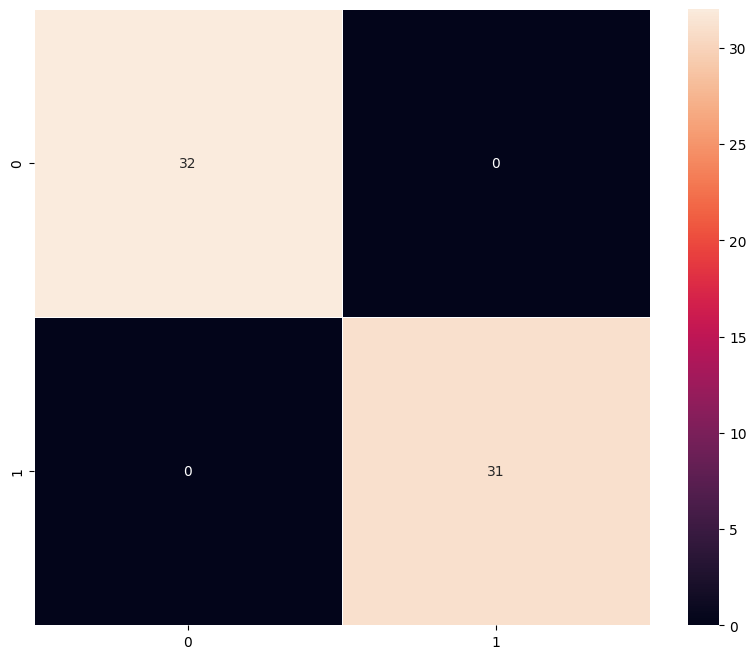

In [ ]:
plot_confusion_matrix(model_2,X_val_pp,y_val)

Observation :    
* The model has 100% accuracy in both training and validation sets.Clearly this model is also overfitting

#### Visualizing the predictions of VGG Base 16 + FFNN




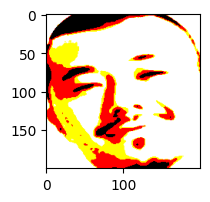

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 455ms/step


Predicted Probability: 2.8537923e-07
Predicted Label: 0
True Label: Label    0
Name: 603, dtype: int64


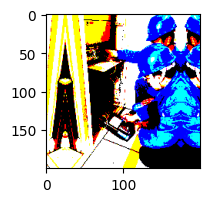

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 33ms/step


Predicted Probability: 1.0
Predicted Label: 1
True Label: Label    1
Name: 59, dtype: int64


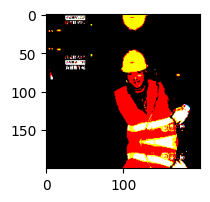

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 44ms/step
Predicted Probability: 1.0
Predicted Label: 1
True Label: Label    1
Name: 175, dtype: int64


In [ ]:
# Visualizing the predicted and correct label of images from validation data
# Sample 1
plt.figure(figsize=(2,2))
plt.imshow(X_val_pp[2])
plt.show()

pred_prob = model_2.predict(X_val_pp[2].reshape(1,200,200,3))[0][0]
pred_label = 1 if pred_prob > 0.5 else 0

print("Predicted Probability:", pred_prob)
print("Predicted Label:", pred_label)
print("True Label:", y_val.iloc[2])

# Sample 2
plt.figure(figsize=(2,2))
plt.imshow(X_val_pp[10])
plt.show()

pred_prob = model_2.predict(X_val_pp[10].reshape(1,200,200,3))[0][0]
pred_label = 1 if pred_prob > 0.5 else 0

print("Predicted Probability:", pred_prob)
print("Predicted Label:", pred_label)
print("True Label:", y_val.iloc[10])

# Sample 3
plt.figure(figsize=(2,2))
plt.imshow(X_val_pp[23])
plt.show()

pred_prob = model_2.predict(X_val_pp[23].reshape(1,200,200,3))[0][0]
pred_label = 1 if pred_prob > 0.5 else 0

print("Predicted Probability:", pred_prob)
print("Predicted Label:", pred_label)
print("True Label:", y_val.iloc[23])

## Model 4: (VGG-16 (Base + Data Augmentation)

- In most of the real-world case studies, it is challenging to acquire a large number of images and then train CNNs.
- To overcome this problem, one approach we might consider is **Data Augmentation**.
- CNNs have the property of **translational invariance**, which means they can recognise an object even if its appearance shifts translationally in some way. - Taking this attribute into account, we can augment the images using the techniques listed below

    -  Horizontal Flip (should be set to True/False)
    -  Vertical Flip (should be set to True/False)
    -  Height Shift (should be between 0 and 1)
    -  Width Shift (should be between 0 and 1)
    -  Rotation (should be between 0 and 180)
    -  Shear (should be between 0 and 1)
    -  Zoom (should be between 0 and 1) etc.

Remember, **data augmentation should not be used in the validation/test data set**.

In [ ]:
K.clear_session()
gc.collect()



0

In [ ]:
vgg_model = VGG16(weights='imagenet',include_top=False,input_shape=(200,200,3))
vgg_model.summary()

Model: "vgg16"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 200, 200, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_conv1 (Conv2D)           │ (None, 200, 200, 64)   │         1,792 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_conv2 (Conv2D)           │ (None, 200, 200, 64)   │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_pool (MaxPooling2D)      │ (None, 100, 100, 64)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_conv1 (Conv2D)           │ (None, 100, 100, 128)  │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_conv2 (Conv2D)           │ (None, 100, 100, 128)  │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_pool (MaxPooling2D)      │ (None, 50, 50, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv1 (Conv2D)           │ (None, 50, 50, 256)    │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv2 (Conv2D)           │ (None, 50, 50, 256)    │       590,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv3 (Conv2D)           │ (None, 50, 50, 256)    │       590,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_pool (MaxPooling2D)      │ (None, 25, 25, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_conv1 (Conv2D)           │ (None, 25, 25, 512)    │     1,180,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_conv2 (Conv2D)           │ (None, 25, 25, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_conv3 (Conv2D)           │ (None, 25, 25, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_pool (MaxPooling2D)      │ (None, 12, 12, 512)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_conv1 (Conv2D)           │ (None, 12, 12, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_conv2 (Conv2D)           │ (None, 12, 12, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_conv3 (Conv2D)           │ (None, 12, 12, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_pool (MaxPooling2D)      │ (None, 6, 6, 512)      │             0 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 14,714,688 (56.13 MB)

 Trainable params: 14,714,688 (56.13 MB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
# Making all the layers of the VGG model non-trainable. i.e. freezing them
for layer in vgg_model.layers:
    layer.trainable = False

In [ ]:
model_3 = Sequential()

# Adding the convolutional part of the VGG16 model from above
model_3.add(vgg_model)

# Aggregating spatial information across feature maps using Global Average Pooling
model_3.add(GlobalAveragePooling2D())

# Adding a dense output layer
model_3.add(Dense(1, activation='sigmoid'))

In [ ]:
opt=Adam()
# Compile model
model_3.compile(optimizer=opt, loss='binary_crossentropy', metrics=['accuracy'])

In [ ]:
# Generating the summary of the model
model_3.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ vgg16 (Functional)              │ (None, 6, 6, 512)      │    14,714,688 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 512)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 1)              │           513 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 14,715,201 (56.13 MB)

 Trainable params: 513 (2.00 KB)

 Non-trainable params: 14,714,688 (56.13 MB)

In [ ]:
# Applying data augmentation
train_datagen = ImageDataGenerator(
                              rotation_range=20,
                              fill_mode='nearest',
                              width_shift_range=0.2,
                              height_shift_range=0.2,
                              shear_range=0.3,
                              zoom_range=0.4
                              )

In [ ]:
history_vgg16 = model_3.fit(train_datagen.flow(X_train_pp,y_train,
                                       batch_size=batch_size,
                                       seed=42,
                                       shuffle=True),
                    epochs=epochs,
                    steps_per_epoch=X_train_pp.shape[0] // batch_size,
                    validation_data=(X_val_pp,y_val),
                    verbose=1)

Epoch 1/20
31/31 ━━━━━━━━━━━━━━━━━━━━ 11s 285ms/step - accuracy: 0.5824 - loss: 1.2914 - val_accuracy: 0.8730 - val_loss: 0.3262
Epoch 2/20
31/31 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - accuracy: 1.0000 - loss: 0.1595 - val_accuracy: 0.8889 - val_loss: 0.3009
Epoch 3/20
31/31 ━━━━━━━━━━━━━━━━━━━━ 6s 188ms/step - accuracy: 0.9232 - loss: 0.2116 - val_accuracy: 0.9841 - val_loss: 0.0664
Epoch 4/20
31/31 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - accuracy: 0.9375 - loss: 0.1223 - val_accuracy: 0.9841 - val_loss: 0.0650
Epoch 5/20
31/31 ━━━━━━━━━━━━━━━━━━━━ 6s 197ms/step - accuracy: 0.9730 - loss: 0.0758 - val_accuracy: 0.9841 - val_loss: 0.0318
Epoch 6/20
31/31 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - accuracy: 0.9375 - loss: 0.1148 - val_accuracy: 0.9841 - val_loss: 0.0306
Epoch 7/20
31/31 ━━━━━━━━━━━━━━━━━━━━ 6s 179ms/step - accuracy: 0.9925 - loss: 0.0289 - val_accuracy: 0.9841 - val_loss: 0.0232
Epoch 8/20
31/31 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - accuracy: 1.0000 - loss: 0.0074 - val_accuracy: 0.984

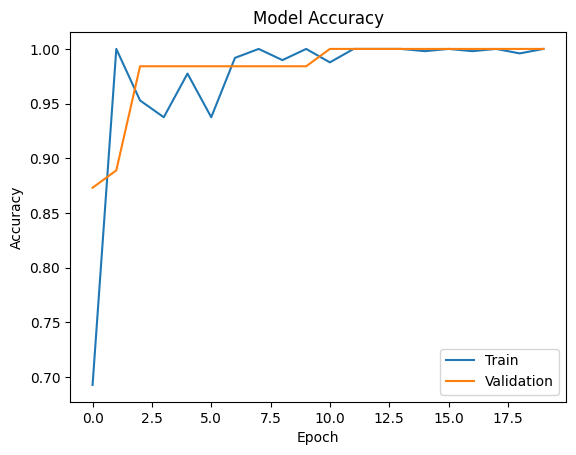

In [ ]:
plt.plot(history_vgg16.history['accuracy'])
plt.plot(history_vgg16.history['val_accuracy'])
plt.title('Model Accuracy')
plt.ylabel('Accuracy')
plt.xlabel('Epoch')
plt.legend(['Train', 'Validation'], loc='lower right')
plt.show()

In [ ]:
model_3_train_perf = model_performance_classification(model_3, X_train_pp,y_train)

print("Train performance metrics")
print(model_3_train_perf)

16/16 ━━━━━━━━━━━━━━━━━━━━ 4s 217ms/step
Train performance metrics
   Accuracy  Recall  Precision  F1 Score
0       1.0     1.0        1.0       1.0


16/16 ━━━━━━━━━━━━━━━━━━━━ 3s 160ms/step


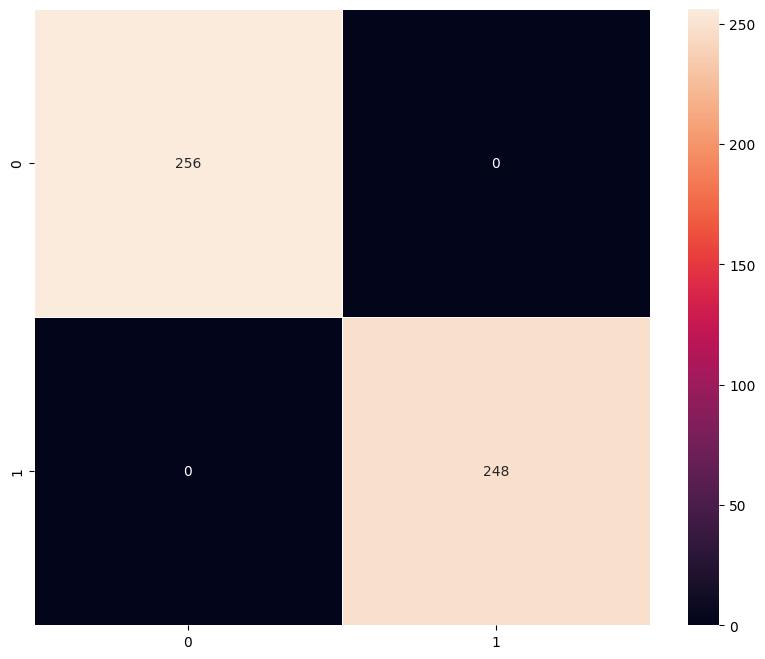

In [ ]:
plot_confusion_matrix(model_3,X_train_pp,y_train)

In [ ]:
model_3_valid_perf = model_performance_classification(model_3, X_val_pp,y_val)

print("Validation performance metrics")
print(model_3_valid_perf)

2/2 ━━━━━━━━━━━━━━━━━━━━ 1s 560ms/step
Validation performance metrics
   Accuracy  Recall  Precision  F1 Score
0       1.0     1.0        1.0       1.0


2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 168ms/step


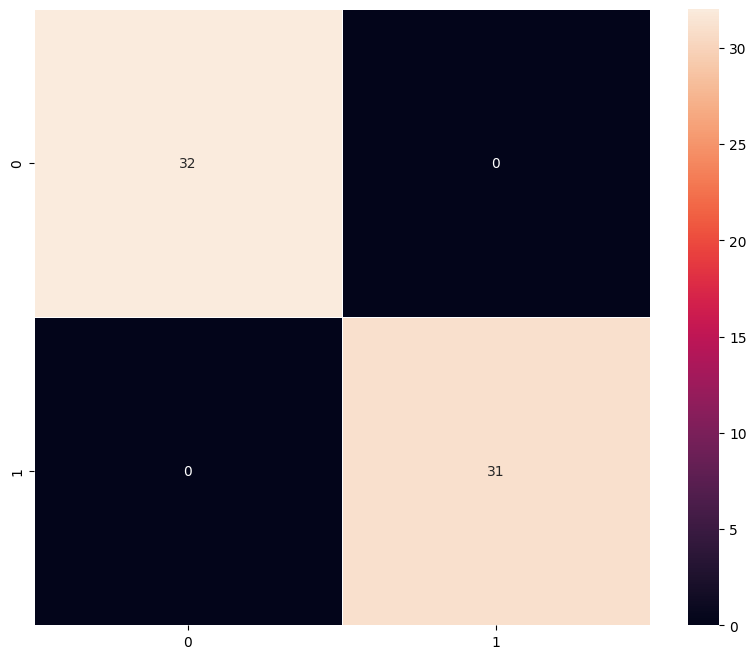

In [ ]:
plot_confusion_matrix(model_3,X_val_pp,y_val)

#### Visualizing the predictions

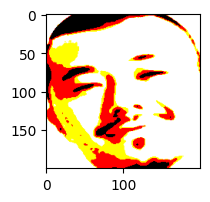

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 432ms/step


Predicted Probability: 0.008294206
Predicted Label: 0
True Label: Label    0
Name: 603, dtype: int64


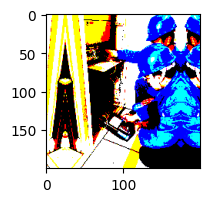

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 33ms/step


Predicted Probability: 1.0
Predicted Label: 1
True Label: Label    1
Name: 59, dtype: int64


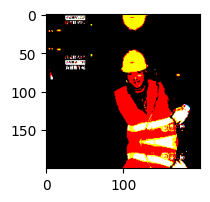

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 35ms/step
Predicted Probability: 1.0
Predicted Label: 1
True Label: Label    1
Name: 175, dtype: int64


In [ ]:
# Visualizing the predicted and correct label of images from test data
# Sample 1
plt.figure(figsize=(2,2))
plt.imshow(X_val_pp[2])
plt.show()

pred_prob = model_3.predict(X_val_pp[2].reshape(1,200,200,3))[0][0]
pred_label = 1 if pred_prob > 0.5 else 0

print("Predicted Probability:", pred_prob)
print("Predicted Label:", pred_label)
print("True Label:", y_val.iloc[2])

# Sample 2
plt.figure(figsize=(2,2))
plt.imshow(X_val_pp[10])
plt.show()

pred_prob = model_3.predict(X_val_pp[10].reshape(1,200,200,3))[0][0]
pred_label = 1 if pred_prob > 0.5 else 0

print("Predicted Probability:", pred_prob)
print("Predicted Label:", pred_label)
print("True Label:", y_val.iloc[10])

# Sample 3
plt.figure(figsize=(2,2))
plt.imshow(X_val_pp[23])
plt.show()

pred_prob = model_3.predict(X_val_pp[23].reshape(1,200,200,3))[0][0]
pred_label = 1 if pred_prob > 0.5 else 0

print("Predicted Probability:", pred_prob)
print("Predicted Label:", pred_label)
print("True Label:", y_val.iloc[23])

# **Model Performance Comparison and Final Model Selection**

In [ ]:
# training performance comparison

models_train_comp_df = pd.concat(
    [
        CNN_train_perf.T,
        model_1_train_perf.T,
        model_2_train_perf.T,
        model_3_train_perf.T,
    ],
    axis=1,
)
models_train_comp_df.columns = [
   "Simple-CNN","VGG-16 (Base)","VGG-16 (Base+FFNN)","VGG-16 (Base+Data Aug)"
]

In [ ]:
models_valid_comp_df = pd.concat(
    [
        CNN_valid_perf.T,
        model_1_valid_perf.T,
        model_2_valid_perf.T,
        model_3_valid_perf.T,

    ],
    axis=1,
)
models_valid_comp_df.columns = [
 "Simple-CNN","VGG-16 (Base)","VGG-16 (Base+FFNN)","VGG-16 (Base+Data Aug)"
]

In [ ]:
models_train_comp_df

,Simple-CNN,VGG-16 (Base),VGG-16 (Base+FFNN),VGG-16 (Base+Data Aug)
Accuracy,0.968254,1.0,1.0,1.0
Recall,0.968254,1.0,1.0,1.0
Precision,0.969296,1.0,1.0,1.0
F1 Score,0.968224,1.0,1.0,1.0


In [ ]:
models_train_comp_df - models_valid_comp_df

,Simple-CNN,VGG-16 (Base),VGG-16 (Base+FFNN),VGG-16 (Base+Data Aug)
Accuracy,0.000000,0.0,0.0,0.0
Recall,0.000000,0.0,0.0,0.0
Precision,-0.000825,0.0,0.0,0.0
F1 Score,0.000018,0.0,0.0,0.0


## Test Performance

In [ ]:
model_test_perf = model_performance_classification(model, X_test_normalized,y_test)

2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 42ms/step


In [ ]:
model_test_perf

,Accuracy,Recall,Precision,F1 Score
0,0.921875,0.921875,0.932432,0.921395


2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 85ms/step 


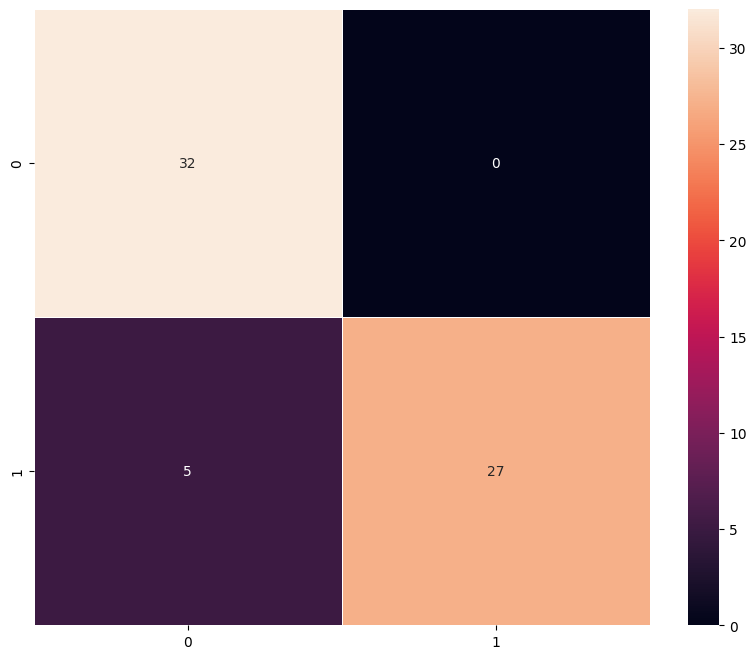

In [ ]:
plot_confusion_matrix(model, X_test_normalized,y_test)

Observation:
* For classification of Helmnet the Simple CNN Model is performing well with commendable accuracy

# **Actionable Insights & Recommendations**

* All the VGG-16-based models are experiencing overfitting.
* Although the performance of Model  is not on par with Models 1 , 2, Model 3 it does not suffer from overfitting.
* These models can be further improved by training with different filter sizes and different number of filters.
* Data Augmentation can be performed more and dropout_rate can be changed to improve the model performance.
* Other Transfer Learning architectures can also be used to train the CNN model and these models can be used for classification.
* The SafeGuard Company can also diversify its dataset by including more images.
